# Programação para Dados — Fase II
**Fun Corp. · Análise do catálogo de jogos da Steam** (pandas, numpy e matplotlib)

Organização do projeto:
- `preprocessamento.py` — carga e limpeza dos dados (funções documentadas e com doctests)
- `estilo.py` + `estilo_fun_corp.mplstyle` — estilo visual padronizado de todas as figuras
- este notebook — consultas e gráficos; as figuras também são salvas em `figuras/`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import estilo
from estilo import AZUL, LARANJA, VERDE, CINZA, pt_br
from preprocessamento import carregar_jogos

estilo.aplicar_estilo()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

## 1. Carga e pré-processamento

In [2]:
df = carregar_jogos("data/steam_games.csv")
print(f"{len(df)} jogos · datas de {df.data_lancamento.min():%d/%m/%Y} a {df.data_lancamento.max():%d/%m/%Y}")
print("AppIDs duplicados:", df.app_id.duplicated().sum())
print("\nValores ausentes por coluna (apenas colunas com ausência):")
print(df.isna().sum()[lambda s: s > 0])
df.head(3)

5199 jogos · datas de 01/05/2003 a 23/07/2022
AppIDs duplicados: 0

Valores ausentes por coluna (apenas colunas com ausência):
nota_metacritic    4889
dtype: int64


,app_id,nome,data_lancamento,preco,windows,mac,linux,nota_metacritic,dlcs,positivas,negativas,generos,categorias,publicadoras,n_capturas,n_filmes,donos_estimados,ano,n_midias,pago
0,20200,Galactic Bowling,2008-10-21,19.99,True,False,False,NaN,0,6,11,"[Casual, Indie, Sports]","[Single-player, Multi-player, Steam Achievements, Partia...",[Perpetual FX Creative],10,1,10000.0,2008,11,True
1,655370,Train Bandit,2017-10-12,0.99,True,True,False,NaN,0,53,5,"[Action, Indie]","[Single-player, Steam Achievements, Full controller supp...",[Wild Rooster],5,1,10000.0,2017,6,True
2,1732930,Jolt Project,2021-11-17,4.99,True,False,False,NaN,0,0,0,"[Action, Adventure, Indie, Strategy]",[Single-player],[Campião Games],6,2,10000.0,2021,8,True


**Decisões de pré-processamento** (detalhadas em `preprocessamento.py`):
- *Datas*: formatos `"Oct 21, 2008"` e `"Oct 2008"` (dia 1) convertidos para `datetime`.
- *Metacritic*: nota `0` significa "sem nota" no arquivo; foi convertida para `NaN` (só 310 dos 5.199 jogos têm nota).
- *Gêneros, categorias e empresas*: campos de texto separados por vírgula viram listas. Nas empresas, vírgulas antes de sufixos como `Inc.`/`Ltd.` não separam empresas (ex.: `KOEI TECMO GAMES CO., LTD.` é uma só).
- *Mídias de demonstração*: contagem de links em `Screenshots` e `Movies` (vazio = 0).
- *Jogo pago*: preço > 0 (mesmo critério da Fase I).

## 2. Pergunta 1 — Dez jogos mais bem avaliados no Metacritic

In [3]:
com_nota = df.dropna(subset=["nota_metacritic"])
top10 = (com_nota
         .sort_values(["nota_metacritic", "data_lancamento"], ascending=[False, True])
         .head(10)[["nome", "nota_metacritic", "data_lancamento"]]
         .reset_index(drop=True))
top10.index += 1
top10["nota_metacritic"] = top10["nota_metacritic"].astype(int)
top10["data_lancamento"] = top10["data_lancamento"].dt.strftime("%d/%m/%Y")
display(top10)

# Desempate na fronteira do top 10: quantos jogos têm a nota do 10º colocado?
nota_corte = top10["nota_metacritic"].iloc[-1]
empatados = com_nota[com_nota.nota_metacritic == nota_corte].sort_values("data_lancamento")
print(f"\nJogos com nota {nota_corte} (nota do 10º colocado): {len(empatados)}")
display(empatados[["nome", "data_lancamento"]].assign(
    data_lancamento=lambda d: d.data_lancamento.dt.strftime("%d/%m/%Y")).reset_index(drop=True))

,nome,nota_metacritic,data_lancamento
1,Call of Duty® 4: Modern Warfare®,92,12/11/2007
2,Freespace 2,91,06/06/2014
3,Half-Life 2: Episode Two,90,10/10/2007
4,Stephen's Sausage Roll,90,17/04/2016
5,Opus Magnum,90,07/12/2017
6,Max Payne,89,06/01/2011
7,Neon White,89,16/06/2022
8,Sid Meier's Pirates!,88,11/07/2005
9,F.E.A.R.,88,21/05/2010
10,Assassin’s Creed® Brotherhood,88,22/03/2011



Jogos com nota 88 (nota do 10º colocado): 9


,nome,data_lancamento
0,Sid Meier's Pirates!,11/07/2005
1,F.E.A.R.,21/05/2010
2,Assassin’s Creed® Brotherhood,22/03/2011
3,The Witcher 2: Assassins of Kings Enhanced Edition,16/04/2012
4,Owlboy,01/11/2016
5,Cuphead,29/09/2017
6,Sekiro™: Shadows Die Twice - GOTY Edition,21/03/2019
7,Ori and the Will of the Wisps,10/03/2020
8,Apex Legends™,04/11/2020


## 3. Pergunta 2 — Jogos de role-playing (gênero `RPG`)

In [4]:
rpg = df[df.generos.map(lambda g: "RPG" in g)]
metricas = {"dlcs": "DLCs", "positivas": "Avaliações positivas",
            "negativas": "Avaliações negativas", "n_midias": "Materiais de demonstração"}
q2 = rpg[list(metricas)].agg(["mean", "max"]).T.rename(columns={"mean": "média", "max": "máximo"})
q2.index = [metricas[i] for i in q2.index]
print(f"{len(rpg)} jogos RPG")
display(q2.round(2))

# Quem são os jogos que têm os valores máximos?
for col, nome in metricas.items():
    linha = rpg.loc[rpg[col].idxmax()]
    print(f"Máximo de {nome}: {int(linha[col])} -> {linha['nome']}")

862 jogos RPG


,média,máximo
DLCs,0.52,22.0
Avaliações positivas,1444.30,154845.0
Avaliações negativas,358.05,103661.0
Materiais de demonstração,11.41,68.0


Máximo de DLCs: 22 -> Crystar
Máximo de Avaliações positivas: 154845 -> Fallout: New Vegas
Máximo de Avaliações negativas: 103661 -> 鬼谷八荒 Tale of Immortal
Máximo de Materiais de demonstração: 68 -> War Ghost


## 4. Pergunta 3 — Empresas que mais publicam jogos pagos

In [5]:
# Um jogo com várias publicadoras conta uma vez para cada uma; jogos sem publicadora ficam de fora.
pagos = df[df.pago].explode("publicadoras").dropna(subset=["publicadoras"])
contagem = pagos.groupby("publicadoras").size().sort_values(ascending=False)
print("Maiores contagens de jogos pagos:")
display(contagem.head(8).to_frame("jogos pagos"))

corte = contagem.iloc[4]                     # valor do 5º colocado
top = contagem[contagem >= corte].index      # inclui empatados no 5º lugar
q3 = (pagos[pagos.publicadoras.isin(top)]
      .groupby("publicadoras")["positivas"]
      .agg(jogos_pagos="count", media_positivas="mean", mediana_positivas="median")
      .sort_values(["jogos_pagos", "media_positivas"], ascending=[False, False]))
display(q3.round(1))
print(f"Empate no 5º lugar ({corte} jogos): {', '.join(contagem[contagem == corte].index)}")

Maiores contagens de jogos pagos:


,jogos pagos
publicadoras,
Big Fish Games,35
8floor,18
SEGA,16
Laush Studio,14
Ubisoft,13
Choice of Games,13
"KOEI TECMO GAMES CO., LTD.",12
Plug In Digital,12


,jogos_pagos,media_positivas,mediana_positivas
publicadoras,,,
Big Fish Games,35,12.5,7.0
8floor,18,5.6,3.5
SEGA,16,2530.9,400.5
Laush Studio,14,25.2,18.0
Ubisoft,13,61684.8,1949.0
Choice of Games,13,18.5,9.0


Empate no 5º lugar (13 jogos): Ubisoft, Choice of Games


## 5. Pergunta 4 — O número de jogos com suporte a Linux cresceu entre 2018 e 2022?

In [6]:
anos = range(2018, 2023)
por_ano = (df[df.ano.isin(anos)]
           .groupby("ano")
           .agg(lancamentos=("linux", "size"), com_linux=("linux", "sum")))
por_ano["% com Linux"] = 100 * por_ano.com_linux / por_ano.lancamentos
display(por_ano.round(1))

# O arquivo termina em 23/07/2022, então 2022 está incompleto.
# Comparação justa: apenas lançamentos de 1º de janeiro a 23 de julho de cada ano.
ate_23_jul = df[df.ano.isin(anos) & (df.data_lancamento.dt.strftime("%m-%d") <= "07-23")]
mesmo_periodo = (ate_23_jul.groupby("ano")
                 .agg(lancamentos=("linux", "size"), com_linux=("linux", "sum")))
mesmo_periodo["% com Linux"] = 100 * mesmo_periodo.com_linux / mesmo_periodo.lancamentos
print("\nMesmo período (1º jan a 23 jul) em cada ano:")
display(mesmo_periodo.round(1))

ini, fim = mesmo_periodo.com_linux.loc[2018], mesmo_periodo.com_linux.loc[2022]
print(f"Mesmo período: {ini} (2018) -> {fim} (2022): variação de {100*(fim-ini)/ini:+.1f}%")

,lancamentos,com_linux,% com Linux
ano,,,
2018,660,80,12.1
2019,648,87,13.4
2020,822,97,11.8
2021,1048,105,10.0
2022,604,60,9.9



Mesmo período (1º jan a 23 jul) em cada ano:


,lancamentos,com_linux,% com Linux
ano,,,
2018,371,47,12.7
2019,333,41,12.3
2020,413,56,13.6
2021,560,54,9.6
2022,604,60,9.9


Mesmo período: 47 (2018) -> 60 (2022): variação de +27.7%


## 6. Pergunta 5 (própria) — Quais gêneros geram mais receita estimada e quão concentrada ela é?
**Receita estimada** de um jogo pago = preço × ponto médio da faixa de *Estimated owners*. É uma aproximação:
usa o preço atual, ignora DLCs e microtransações e depende de faixas largas de donos.
Um jogo com vários gêneros conta em cada um deles, então os totais por gênero não se somam.
Consideram-se apenas gêneros de jogo (excluídos `Early Access`, que é status de desenvolvimento, `Free to Play` e softwares como `Utilities`).

In [7]:
GENEROS_DE_JOGO = ["Action", "Adventure", "Indie", "Simulation", "RPG", "Strategy",
                   "Casual", "Massively Multiplayer", "Racing", "Sports"]

pagos_jogos = df[df.pago].copy()
pagos_jogos["receita"] = pagos_jogos.preco * pagos_jogos.donos_estimados

por_genero = (pagos_jogos.explode("generos")
              .query("generos in @GENEROS_DE_JOGO")
              .groupby("generos")["receita"]
              .agg(jogos="size", total="sum", media="mean", mediana="median")
              .sort_values("total", ascending=False))
tabela = por_genero.assign(total=lambda d: d.total / 1e6,
                           media=lambda d: d.media / 1e3,
                           mediana=lambda d: d.mediana / 1e3)
tabela.columns = ["jogos pagos", "total (US$ mi)", "média por jogo (US$ mil)", "mediana por jogo (US$ mil)"]
display(tabela.round(1))

# Concentração: quanto da receita total vem dos jogos mais lucrativos?
ordenada = pagos_jogos.receita.sort_values(ascending=False)
total = ordenada.sum()
n1 = int(np.ceil(0.01 * len(ordenada)))
print(f"Receita total estimada (jogos pagos): US$ {total/1e9:.2f} bi em {len(ordenada)} jogos")
print(f"Top 1% dos jogos ({n1}) concentram {100*ordenada.head(n1).sum()/total:.1f}% da receita")
print(f"Top 10% dos jogos ({int(0.1*len(ordenada))}) concentram {100*ordenada.head(int(0.1*len(ordenada))).sum()/total:.1f}% da receita")
print(f"Metade 'de baixo' dos jogos concentra {100*ordenada.tail(len(ordenada)//2).sum()/total:.2f}% da receita")
print("Jogos com receita estimada zero (0 donos estimados):", int((ordenada == 0).sum()))

,jogos pagos,total (US$ mi),média por jogo (US$ mil),mediana por jogo (US$ mil)
generos,,,,
Action,1824,4363.7,2392.4,79.9
Adventure,1710,3123.2,1826.4,89.9
Indie,3182,2906.4,913.4,59.9
Simulation,821,1859.6,2265.0,99.9
RPG,716,1707.9,2385.3,119.9
Strategy,805,1284.5,1595.7,99.9
Casual,1820,680.2,373.7,49.9
Massively Multiplayer,57,429.9,7541.5,109.9
Racing,157,423.1,2695.1,69.9


Receita total estimada (jogos pagos): US$ 7.06 bi em 4348 jogos
Top 1% dos jogos (44) concentram 59.6% da receita
Top 10% dos jogos (434) concentram 93.2% da receita
Metade 'de baixo' dos jogos concentra 1.02% da receita
Jogos com receita estimada zero (0 donos estimados): 14


## 7. Gráficos

### Gráfico 1 — Suporte por sistema operacional

{'Windows': 5193, 'macOS': 1150, 'Linux': 770} | total de votos: 7113


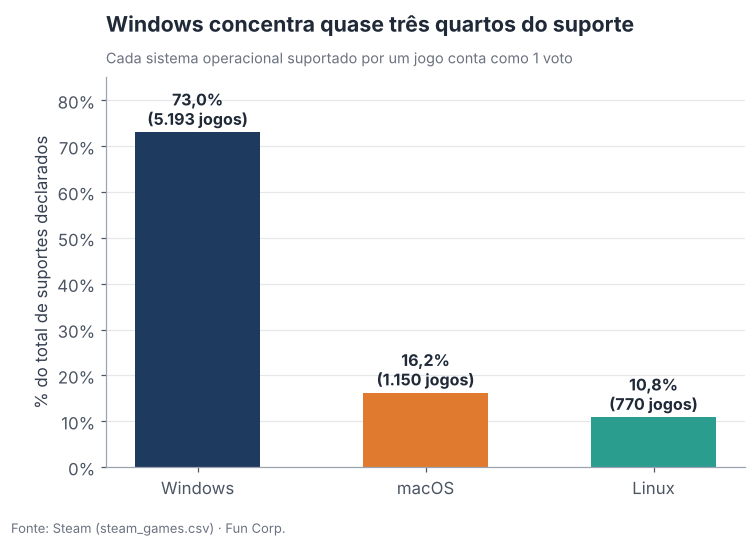

In [8]:
votos = df[["windows", "mac", "linux"]].sum()
votos.index = ["Windows", "macOS", "Linux"]
percentual = 100 * votos / votos.sum()
print(votos.to_dict(), "| total de votos:", int(votos.sum()))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
barras = ax.bar(percentual.index, percentual.values, color=[AZUL, LARANJA, VERDE], width=0.55)
for barra, v, n in zip(barras, percentual.values, votos.values):
    ax.annotate(f"{pt_br(v)}%\n({pt_br(n, 0)} jogos)", (barra.get_x() + barra.get_width() / 2, v),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10.5, fontweight="bold")
ax.set_ylim(0, 85)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("% do total de suportes declarados")
ax.grid(axis="x", visible=False)
estilo.titulo(ax, "Windows concentra quase três quartos do suporte",
              "Cada sistema operacional suportado por um jogo conta como 1 voto")
estilo.fonte(fig)
fig.savefig("figuras/grafico1_sistemas_operacionais.png")
plt.show()

### Gráfico 2 — Jogos single-player Indie e Strategy lançados por ano (2010–2020)

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Indie,8,7,15,22,83,157,256,351,474,473,598
Strategy,6,3,6,9,23,52,55,70,94,102,158


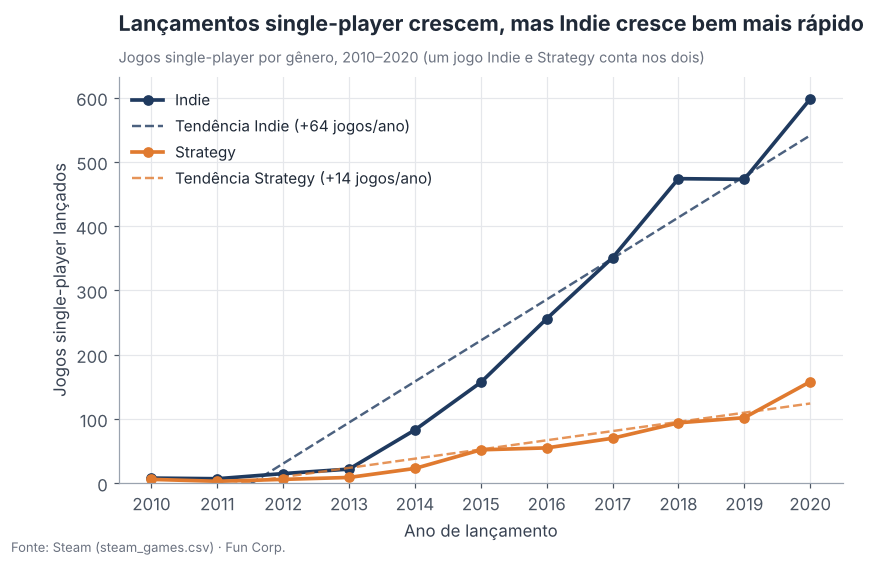

In [9]:
single = df[df.categorias.map(lambda c: "Single-player" in c) & df.ano.between(2010, 2020)]
anos2 = np.arange(2010, 2021)
series = {}
for genero in ["Indie", "Strategy"]:
    sel = single[single.generos.map(lambda g, gen=genero: gen in g)]
    series[genero] = sel.groupby("ano").size().reindex(anos2, fill_value=0)
tabela2 = pd.DataFrame(series)
display(tabela2.T)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (genero, serie), cor in zip(series.items(), [AZUL, LARANJA]):
    ax.plot(anos2, serie.values, marker="o", color=cor, label=genero)
    coef = np.polyfit(anos2, serie.values, 1)          # tendência linear
    ax.plot(anos2, np.polyval(coef, anos2), ls="--", lw=1.6, color=cor, alpha=0.8,
            label=f"Tendência {genero} ({coef[0]:+.0f} jogos/ano)")
ax.set_xticks(anos2)
ax.set_ylim(bottom=0)                       # tendência linear não deve "afundar" abaixo de zero
ax.set_xlabel("Ano de lançamento")
ax.set_ylabel("Jogos single-player lançados")
ax.legend(loc="upper left")
estilo.titulo(ax, "Lançamentos single-player crescem, mas Indie cresce bem mais rápido",
              "Jogos single-player por gênero, 2010–2020 (um jogo Indie e Strategy conta nos dois)")
estilo.fonte(fig)
fig.savefig("figuras/grafico2_indie_estrategia.png")
plt.show()

### Gráfico 3 — Receita estimada por gênero (pergunta 5)

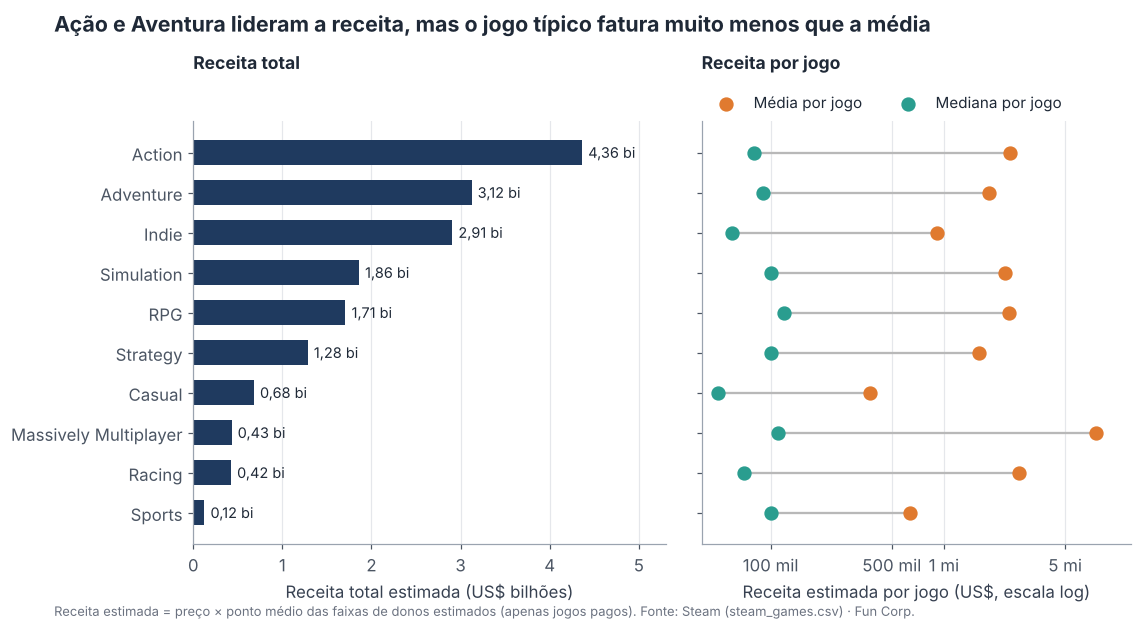

In [10]:
ordem = por_genero.index[::-1]                       # maior no topo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True,
                               gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.08})

# Painel esquerdo: receita total
ax1.barh(ordem, por_genero.total[ordem] / 1e9, color=AZUL, height=0.62)
for i, g in enumerate(ordem):
    ax1.annotate(f"{pt_br(por_genero.total[g] / 1e9, 2)} bi", (por_genero.total[g] / 1e9, i),
                 xytext=(4, 0), textcoords="offset points", va="center", fontsize=9.5)
ax1.set_xlim(0, 5.3)
ax1.set_xlabel("Receita total estimada (US$ bilhões)")
ax1.grid(axis="y", visible=False)
ax1.set_title("Receita total", loc="left", fontsize=11.5, pad=34)

# Painel direito: média x mediana por jogo (escala logarítmica)
ax2.scatter(por_genero.media[ordem] / 1e3, ordem, color=LARANJA, s=70, zorder=3, label="Média por jogo")
ax2.scatter(por_genero.mediana[ordem] / 1e3, ordem, color=VERDE, s=70, zorder=3, label="Mediana por jogo")
for g in ordem:
    ax2.plot([por_genero.mediana[g] / 1e3, por_genero.media[g] / 1e3], [g, g], color=CINZA, lw=1.5, zorder=2)
ax2.set_xscale("log")
ax2.set_xlim(40, 12000)
ax2.set_xticks([100, 500, 1000, 5000])
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{pt_br(v, 0)} mil" if v < 1000 else f"{pt_br(v/1000, 0)} mi"))
ax2.minorticks_off()
ax2.set_xlabel("Receita estimada por jogo (US$, escala log)")
ax2.grid(axis="y", visible=False)
ax2.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, borderaxespad=0.2)
ax2.set_title("Receita por jogo", loc="left", fontsize=11.5, pad=34)

fig.suptitle("Ação e Aventura lideram a receita, mas o jogo típico fatura muito menos que a média",
             x=0.01, y=1.08, ha="left", fontsize=14, fontweight="bold")
estilo.fonte(fig, "Receita estimada = preço × ponto médio das faixas de donos estimados (apenas jogos pagos). Fonte: Steam (steam_games.csv) · Fun Corp.")
fig.savefig("figuras/grafico3_receita_por_genero.png")
plt.show()